# Projet Deep Learning : reconnaissance d'émotions faciales avec un CNN

## Choix du dataset : FER2013
Source : https://www.kaggle.com/datasets/aadityasinghal/facial-expression-dataset

FER2013 contient plus de 35 000 images de visages en niveaux de gris, de taille 48x48, réparties en 7 émotions (colère, dégoût, peur, joie, neutre, tristesse, surprise).

## Importation des librairies

In [ ]:
import os
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
import random
import numpy as np
from tensorflow import keras

## Importation des fichiers .zip
Le dataset est téléchargé depuis Kaggle sous forme de deux archives (train et test). Cette cellule demande l'upload des fichiers dans Colab puis les extrait dans `/content/fer2013`. Elle est commentée pour ne pas être relancée à chaque exécution : il faut la décommenter et l'exécuter **2 fois** (une fois par archive).

In [ ]:

#A decommenter seulement pour importer les .zip
from google.colab import files

uploaded = files.upload()

import os
import zipfile

zip_name = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

extract_dir = "/content/fer2013"

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Dataset extrait dans :", extract_dir)


Saving archive (2).zip to archive (2) (1).zip
Dataset extrait dans : /content/fer2013


## Vérification des classes
On définit les chemins des dossiers `train` et `test`. Chaque sous-dossier correspond à une émotion : Keras s'en servira comme label (ordre alphabétique).

In [ ]:
train_dir = "/content/fer2013/train/train"
test_dir = "/content/fer2013/test/test"

classes = sorted(os.listdir(train_dir))

print("Classes :", classes)

Classes : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


Nous avons bien 7 classes d'émotions différentes.

## Analyse de la répartition des classes dans train
On compte les images par classe et leur pourcentage. Cette étape sert à détecter un éventuel **déséquilibre** : une classe très minoritaire sera plus difficilement apprise, et l'accuracy globale pourrait masquer de mauvaises performances sur celle-ci.

In [ ]:
print("Nombre d'images par classe dans train\n")

nb_images_total=0
for emotion in classes:
    path = os.path.join(train_dir, emotion)
    nb_images = len(os.listdir(path))
    nb_images_total+=nb_images

for emotion in classes:
    path = os.path.join(train_dir, emotion)
    nb_images = len(os.listdir(path))
    print(f"{emotion:10s} : {nb_images}, pourcentage :{nb_images*100/nb_images_total}%")

print(f"\nNombre total d'images dans train : {nb_images_total}")

Nombre d'images par classe dans train

angry      : 3995, pourcentage :13.91549688251071%
disgust    : 436, pourcentage :1.5186875195931588%
fear       : 4097, pourcentage :14.270786164617368%
happy      : 7215, pourcentage :25.13149186666202%
neutral    : 4965, pourcentage :17.294228290779895%
sad        : 4830, pourcentage :16.823992476226966%
surprise   : 3171, pourcentage :11.045316799609878%

Nombre total d'images dans train : 28709


## Analyse de la répartition des classes dans test
Même analyse sur le jeu de test, pour vérifier que sa distribution est proche de celle du train et que l'évaluation finale est représentative.

In [ ]:
print("Nombre d'images par classe dans test\n")

nb_images_total=0
for emotion in classes:
    path = os.path.join(test_dir, emotion)
    nb_images = len(os.listdir(path))
    nb_images_total+=nb_images

for emotion in classes:
    path = os.path.join(test_dir, emotion)
    nb_images = len(os.listdir(path))
    print(f"{emotion:10s} : {nb_images}, pourcentage :{nb_images*100/nb_images_total}%")

print(f"\nNombre total d'images dans test : {nb_images_total}")

Nombre d'images par classe dans test

angry      : 958, pourcentage :13.346336026748398%
disgust    : 111, pourcentage :1.5463917525773196%
fear       : 1024, pourcentage :14.265812203956534%
happy      : 1774, pourcentage :24.71440512677626%
neutral    : 1233, pourcentage :17.17748676511563%
sad        : 1247, pourcentage :17.372527166341598%
surprise   : 831, pourcentage :11.577040958484258%

Nombre total d'images dans test : 7178


## Affichage de plusieurs images par classe
On affiche 5 images tirées au hasard pour chaque émotion. Cela permet de vérifier visuellement que les images sont bien chargées, de voir leur qualité

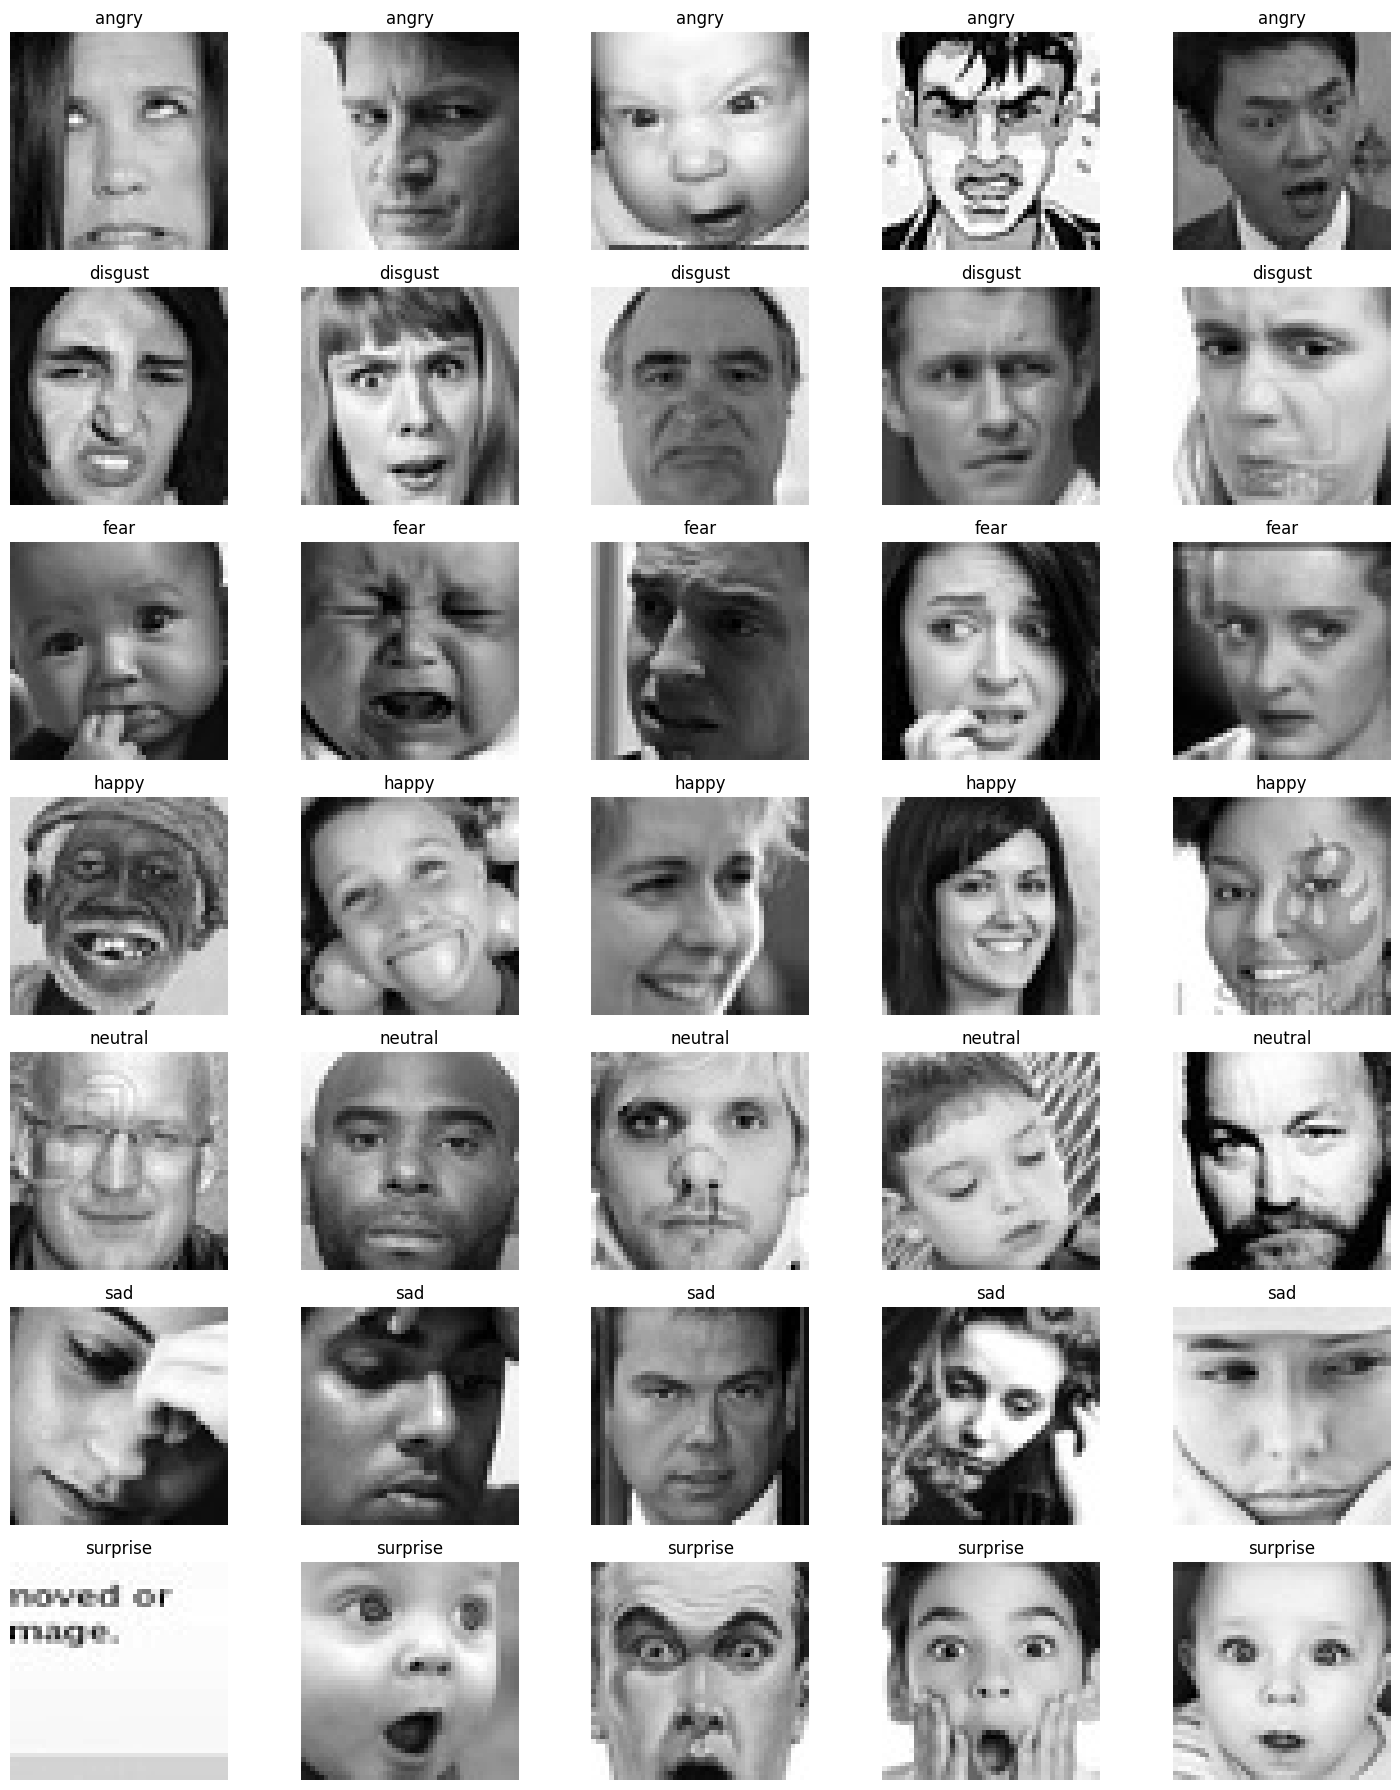

In [ ]:
# Nombre d'images à afficher par classe
n_images = 5

plt.figure(figsize=(15, 18))

for row, emotion in enumerate(classes):

    emotion_dir = os.path.join(train_dir, emotion)
    image_names = os.listdir(emotion_dir)
    selected_images = random.sample(image_names, n_images)

    for col, image_name in enumerate(selected_images):

        image_path = os.path.join(emotion_dir, image_name)
        image = Image.open(image_path)

        position = row * n_images + col + 1

        ax = plt.subplot(len(classes), n_images, position)

        plt.imshow(image, cmap="gray")
        plt.title(emotion)
        plt.axis("off")

plt.tight_layout()
plt.show()

# Mise en place des différents ensembles

On crée les datasets directement depuis les dossiers avec Keras. Le jeu de validation est obtenu en prenant 20 % des images du train (même `seed=42` pour les deux appels afin que les deux sous-ensembles soient bien disjoints). Le jeu de test reste intact et n'est utilisé qu'à la fin. Les images sont lues en niveaux de gris (`color_mode="grayscale"`, 1 canal) et par lots de 32.

In [ ]:
IMG_SIZE = (48, 48)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(48, 48),
    batch_size=BATCH_SIZE,
    color_mode="grayscale"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(48,48),
    batch_size=BATCH_SIZE,
    color_mode="grayscale"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(48, 48),
    batch_size=BATCH_SIZE,
    color_mode="grayscale"
)



Found 28709 files belonging to 7 classes.
Using 22968 files for training.
Found 28709 files belonging to 7 classes.
Using 5741 files for validation.
Found 7178 files belonging to 7 classes.


On vérifie que chaque dataset contient bien les 7 classes, dans le même ordre.

In [ ]:
print("Classes TRAIN :", train_ds.class_names)
print("Classes VALIDATION :", val_ds.class_names)
print("Classes TEST :", test_ds.class_names)

Classes TRAIN : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Classes VALIDATION : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Classes TEST : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


## Normalisation
Les pixels sont des entiers entre 0 et 255. On les ramène entre 0 et 1 avec `Rescaling(1/255)` : des entrées de petite amplitude stabilisent et accélèrent l'apprentissage par descente de gradient. La même transformation est appliquée à train, validation et test.

In [ ]:

normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

test_ds = test_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

# Partie 2 : modèle de référence sans CNN
On construit d'abord un modèle simple, sans convolution, qui servira de baseline pour mesurer l'apport du CNN.

Architecture du modèle sans CNN : les 48x48 pixels sont aplatis (`Flatten`) en un vecteur de 2304 valeurs, passés dans une couche dense de 128 neurones (ReLU), puis une couche de sortie de 7 neurones avec softmax (probabilité par émotion). Ce modèle ignore la structure spatiale de l'image : chaque pixel est traité indépendamment de ses voisins.

In [ ]:
modeleP2 = keras.Sequential([
    keras.layers.Input(shape=(48,48,1)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(7, activation="softmax")
], name="modele_sans_cnn")

modeleP2.summary()

Model: "modele_sans_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 295,943 (1.13 MB)

 Trainable params: 295,943 (1.13 MB)

 Non-trainable params: 0 (0.00 B)

Entraînement : optimiseur `adam` (efficace sans réglage fin), perte `sparse_categorical_crossentropy` (classification multi-classes avec labels entiers, ce que renvoie Keras) et métrique accuracy. 10 époques suffisent pour une baseline.

In [ ]:
modeleP2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_modeleP2 = modeleP2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.2696 - loss: 1.8115 - val_accuracy: 0.2921 - val_loss: 1.7341
Epoch 2/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.3181 - loss: 1.7154 - val_accuracy: 0.3172 - val_loss: 1.7091
Epoch 3/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.3387 - loss: 1.6829 - val_accuracy: 0.3339 - val_loss: 1.6741
Epoch 4/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.3434 - loss: 1.6685 - val_accuracy: 0.3118 - val_loss: 1.7042
Epoch 5/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.3479 - loss: 1.6563 - val_accuracy: 0.3346 - val_loss: 1.6723
Epoch 6/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.3524 - loss: 1.6502 - val_accuracy: 0.3538 - val_loss: 1.6428
Epoch 7/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.3599 - loss: 1.6378 - val_accuracy: 0.3562 - val_loss: 1.6400
Epoch 8/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.3601 - loss: 1.6263 - val_accuracy: 0.

Courbes d'apprentissage : accuracy et loss en train et en validation, pour repérer sous-apprentissage ou surapprentissage. Ces résultats serviront de point de comparaison pour le CNN.

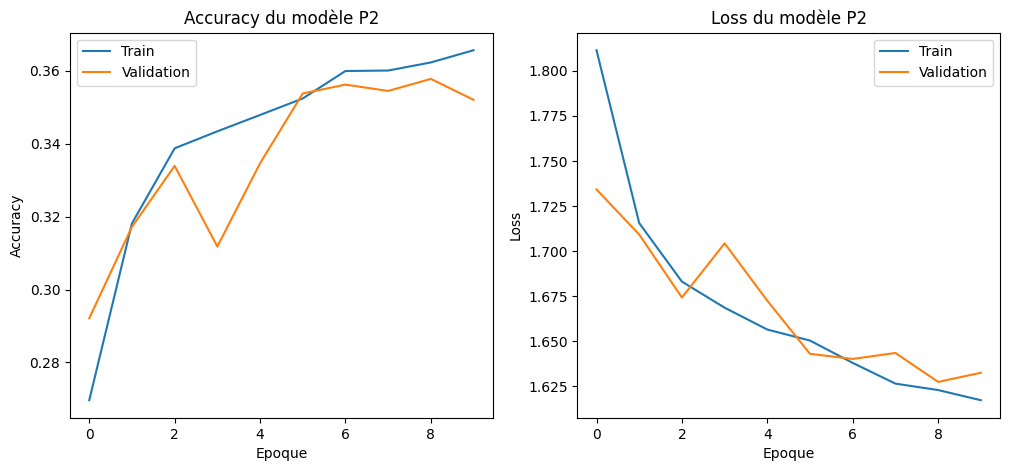

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_modeleP2.history["accuracy"], label="Train")
plt.plot(history_modeleP2.history["val_accuracy"], label="Validation")
plt.title("Accuracy du modèle P2")
plt.xlabel("Epoque")
plt.ylabel("Accuracy")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_modeleP2.history["loss"], label="Train")
plt.plot(history_modeleP2.history["val_loss"], label="Validation")
plt.title("Loss du modèle P2")
plt.xlabel("Epoque")
plt.ylabel("Loss")
plt.legend()
plt.show()

Le modèle sans CNN atteint seulement environ 35 % d’accuracy en validation, ce qui est faible pour une classification en 7 classes. Il aplatit les images et perd donc la structure spatiale du visage. Cela justifie le passage à un CNN, qui devrait donner de bien meilleurs résultats.

# Partie 3 : modèle CNN

Architecture du CNN : trois blocs `Conv2D` + `MaxPooling2D`. Les convolutions 3x3 détectent des motifs locaux (contours, puis formes de la bouche, des yeux, etc.) et le nombre de filtres augmente (32, 64, 128) pour capter des motifs de plus en plus complexes, tandis que le pooling 2x2 divise la taille des cartes de caractéristiques, réduit le nombre de paramètres et apporte une invariance aux petites translations. On aplatit ensuite et on termine par la même tête dense que la baseline (128 neurones + softmax à 7 classes), pour que la comparaison porte sur l'effet des convolutions.

In [ ]:
cnn_modele = keras.models.Sequential([
    keras.layers.Input(shape=(48, 48, 1)),

    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(128, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Flatten(),

    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(7, activation="softmax")
])

cnn_modele.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,847 (1.36 MB)

 Trainable params: 355,847 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Compilation avec les mêmes choix que pour la baseline (Adam, cross-entropy, accuracy).

In [ ]:
cnn_modele.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Entraînement du CNN pendant 20 époques, avec suivi de la validation à chaque époque.

In [ ]:


history_dropout = cnn_modele.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)



Epoch 1/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 15s 14ms/step - accuracy: 0.3255 - loss: 1.6880 - val_accuracy: 0.4118 - val_loss: 1.5299
Epoch 2/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.4489 - loss: 1.4374 - val_accuracy: 0.4700 - val_loss: 1.3881
Epoch 3/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.5021 - loss: 1.3035 - val_accuracy: 0.5003 - val_loss: 1.3074
Epoch 4/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5411 - loss: 1.2118 - val_accuracy: 0.5105 - val_loss: 1.2681
Epoch 5/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5675 - loss: 1.1458 - val_accuracy: 0.5187 - val_loss: 1.2561
Epoch 6/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5943 - loss: 1.0812 - val_accuracy: 0.5266 - val_loss: 1.2517
Epoch 7/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6250 - loss: 1.0117 - val_accuracy: 0.5192 - val_loss: 1.2854
Epoch 8/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.6486 - loss: 0.9475 - val_accuracy: 

On relève la meilleure accuracy et la plus faible loss en validation, puis on trace les courbes. Un écart croissant entre train et validation signale du surapprentissage

Meilleure accuracy validation : 0.5266
Meilleure loss validation : 1.2517


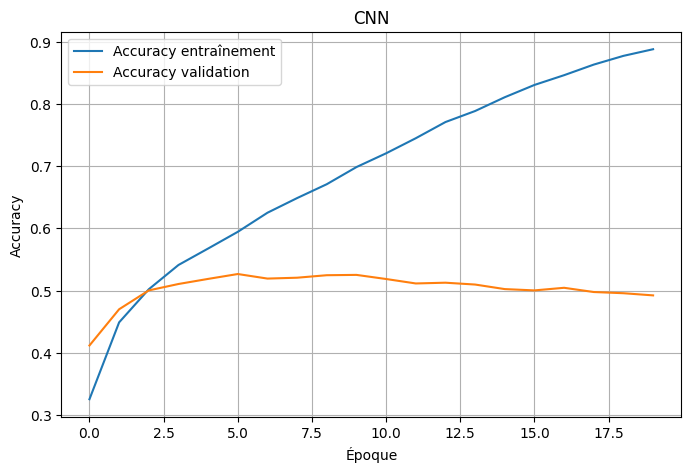

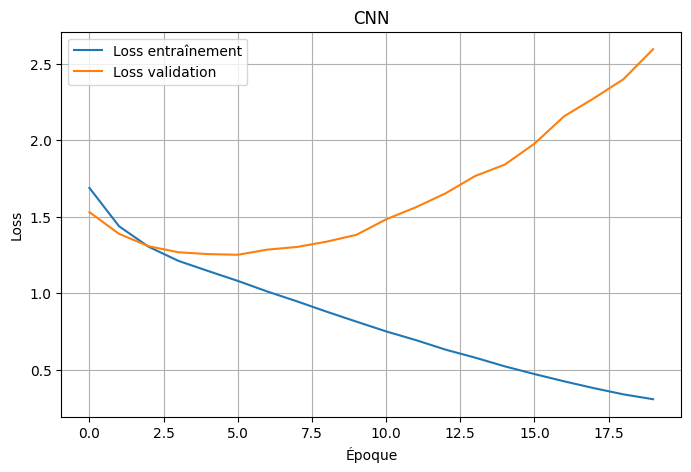

In [ ]:


dropout_val_accuracy = max(history_dropout.history["val_accuracy"])
dropout_val_loss = min(history_dropout.history["val_loss"])

print(f"Meilleure accuracy validation : {dropout_val_accuracy:.4f}")
print(f"Meilleure loss validation : {dropout_val_loss:.4f}")

plt.figure(figsize=(8, 5))

plt.plot(
    history_dropout.history["accuracy"],
    label="Accuracy entraînement"
)

plt.plot(
    history_dropout.history["val_accuracy"],
    label="Accuracy validation"
)

plt.title("CNN")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    history_dropout.history["loss"],
    label="Loss entraînement"
)

plt.plot(
    history_dropout.history["val_loss"],
    label="Loss validation"
)

plt.title("CNN")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()

Le CNN de base améliore nettement les résultats par rapport au modèle sans CNN : l'accuracy de validation atteint environ 50 à 52 %, contre environ 35 % auparavant. En revanche, les courbes montrent un surapprentissage important. L'accuracy d'entraînement monte jusqu'à environ 92 % alors que celle de validation stagne autour de 50 % dès la 5ᵉ époque. La loss de validation est minimale vers l'époque 4-5 (environ 1,25), puis ré-augmente fortement jusqu'à plus de 2,8, alors que la loss d'entraînement continue de baisser. Le modèle mémorise donc les images d'entraînement au lieu de généraliser

# Partie 5 : évaluation sur le jeu de test

On prédit sur tout le jeu de test avec le CNN et on stocke les vraies classes (`y_true`), les classes prédites (`y_pred`, via `argmax`) et les probabilités (`y_proba`). Le test n'a servi ni à l'entraînement ni au choix des hyperparamètres, c'est donc une estimation honnête de la performance.

In [ ]:
y_true = []
y_pred = []
y_proba = []

for images, labels in test_ds:
    predictions = cnn_modele.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))
    y_proba.extend(predictions)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_proba = np.array(y_proba)

print("Nombre d'images test :", len(y_true))
print("Shape y_true :", y_true.shape)
print("Shape y_pred :", y_pred.shape)
print("Shape y_proba :", y_proba.shape)

Nombre d'images test : 7178
Shape y_true : (7178,)
Shape y_pred : (7178,)
Shape y_proba : (7178, 7)


Matrice de confusion : chaque ligne est une vraie classe, chaque colonne une classe prédite. La diagonale correspond aux bonnes prédictions ; les valeurs hors diagonale montrent quelles émotions sont confondues entre elles.

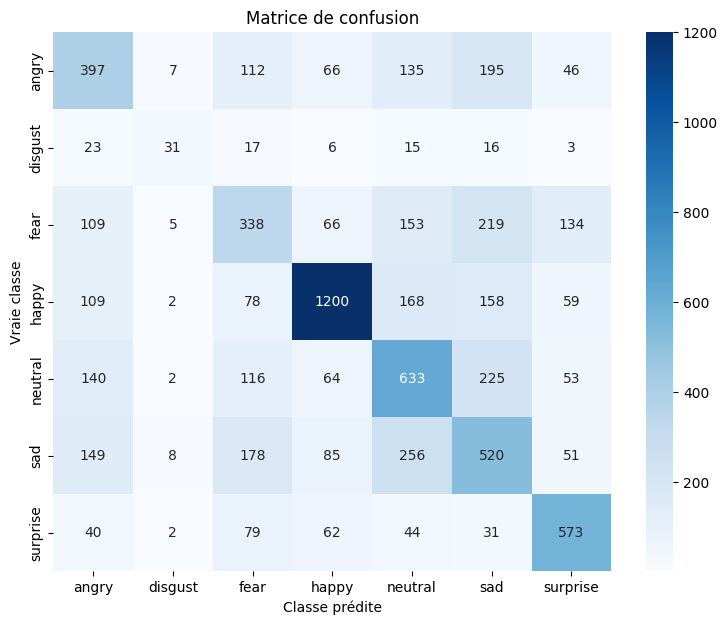

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Classe prédite")
plt.ylabel("Vraie classe")
plt.title("Matrice de confusion")
plt.show()

La matrice de confusion confirme les résultats de validation : l'accuracy sur le test est d'environ 51 % (3 664 images bien classées sur 7 178). La classe happy est de loin la mieux reconnue, avec 1 294 bonnes prédictions sur 1 774 images, soit environ 73 % de rappel. C'est aussi la classe la plus représentée, et son expression (le sourire) est très marquée. surprise est également bien reconnue (environ 64 %), car l'expression est distinctive (bouche et yeux ouverts).

À l'inverse, les émotions négatives ou proches sont souvent confondues entre elles. sad est la classe la moins bien reconnue (environ 35 %) : elle est confondue avec fear (243 cas), neutral (204) et angry (189). fear (environ 39 %) est confondue avec angry, sad et neutral. neutral est souvent prise pour sad (229 cas) ou angry/fear. Ces confusions sont cohérentes avec la difficulté intrinsèque du dataset : sur des images 48×48, ces expressions sont visuellement proches et parfois ambiguës, même pour un humain, et les labels de FER2013 sont bruités.

La classe disgust n'a que 111 images de test, soit très peu. Elle est reconnue dans environ 45 % des cas, mais le faible effectif rend cette statistique peu fiable. Le déséquilibre des classes pénalise les classes minoritaires et favorise happy. Cela justifie de regarder le rapport de classification (précision, rappel, F1 par classe) plutôt que l'accuracy seule.

Rapport de classification : précision, rappel et F1-score par classe. Plus informatif que l'accuracy seule, notamment avec des classes déséquilibrées.

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=classes
    )
)


              precision    recall  f1-score   support

       angry       0.41      0.41      0.41       958
     disgust       0.54      0.28      0.37       111
        fear       0.37      0.33      0.35      1024
       happy       0.77      0.68      0.72      1774
     neutral       0.45      0.51      0.48      1233
         sad       0.38      0.42      0.40      1247
    surprise       0.62      0.69      0.65       831

    accuracy                           0.51      7178
   macro avg       0.51      0.47      0.48      7178
weighted avg       0.52      0.51      0.52      7178



Exemples de prédictions : 9 images de test tirées au hasard (graine fixée pour la reproductibilité), avec vraie classe, classe prédite et probabilité associée. Cela permet d'examiner qualitativement les erreurs et la confiance du modèle.

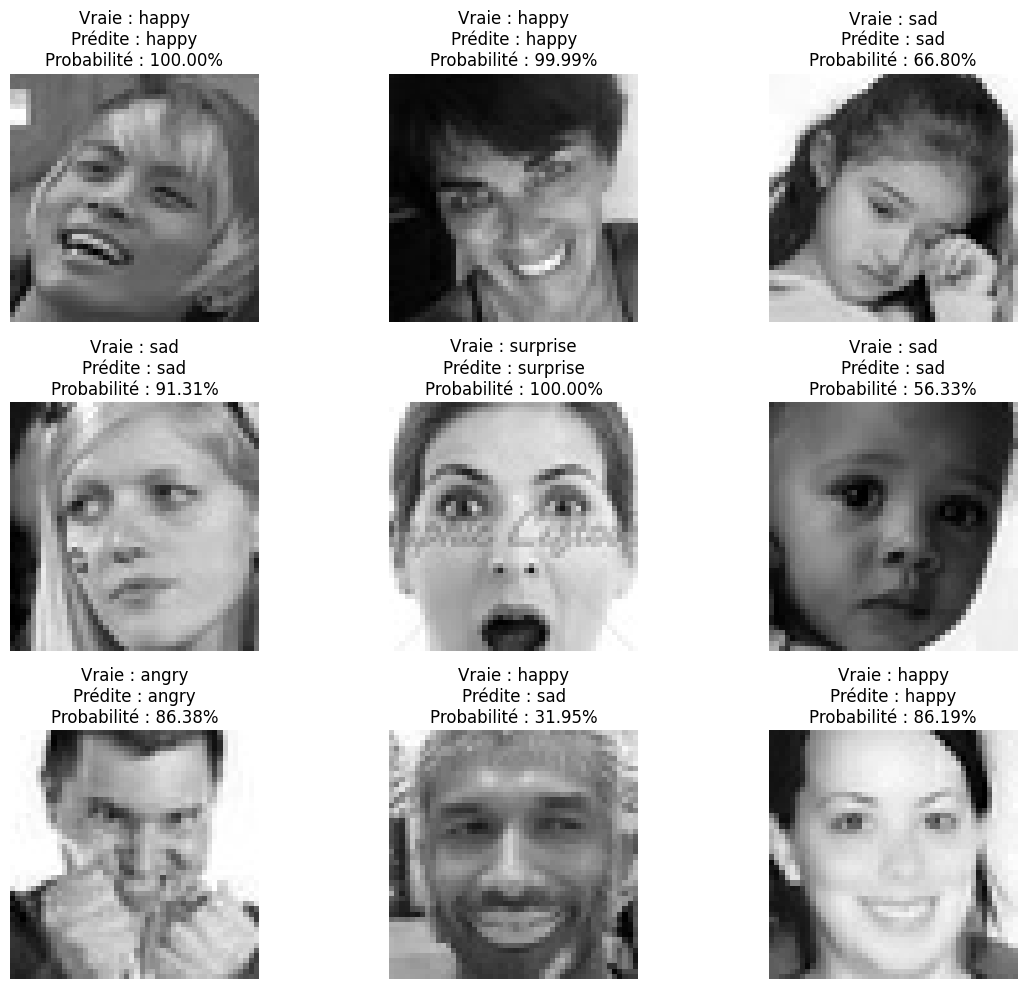

In [ ]:
np.random.seed(164)

test_images = []
test_labels = []

for images, labels in test_ds:
    test_images.extend(images.numpy())
    test_labels.extend(labels.numpy())

test_images = np.array(test_images)
test_labels = np.array(test_labels)

indices = np.random.choice(
    len(test_images),
    size=9,
    replace=False,
)

plt.figure(figsize=(12, 10))

for i, idx in enumerate(indices):
    image = test_images[idx]
    true_label = test_labels[idx]

    probabilities = cnn_modele.predict(
        np.expand_dims(image, axis=0),
        verbose=0
    )[0]

    predicted_label = np.argmax(probabilities)
    confidence = probabilities[predicted_label]

    plt.subplot(3, 3, i + 1)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.axis("off")

    plt.title(
        f"Vraie : {classes[true_label]}\n"
        f"Prédite : {classes[predicted_label]}\n"
        f"Probabilité : {confidence:.2%}"
    )

plt.tight_layout()
plt.show()

# Partie 6 : amélioration du modèle (régularisation)

## Data augmentation
Le CNN de base a tendance à surapprendre. On teste donc des techniques de régularisation, d'abord seules puis combinées, en gardant exactement la même architecture pour comparer équitablement.

Principe : on génère à chaque époque des versions légèrement modifiées des images (retournement horizontal, rotation de 5 %, zoom de 10 %, translation de 5 %). Le modèle voit ainsi des données plus variées, ce qui limite le surapprentissage. Les transformations sont volontairement faibles car un visage trop déformé changerait l'expression ; le flip horizontal est valide car un visage reste cohérent en miroir. La couche d'augmentation n'est active que pendant l'entraînement.

In [ ]:


data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(0.05, 0.05)
])


augmentation_model = keras.models.Sequential([
    keras.layers.Input(shape=(48, 48, 1)),

    data_augmentation,

    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(128, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Flatten(),

    keras.layers.Dense(128, activation="relu"),

    keras.layers.Dense(7, activation="softmax")
])

augmentation_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

augmentation_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,847 (1.36 MB)

 Trainable params: 355,847 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Entraînement du modèle avec data augmentation (20 époques, comme les autres pour comparer).

In [ ]:
history_augmentation = augmentation_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

Epoch 1/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 13s 11ms/step - accuracy: 0.2914 - loss: 1.7508 - val_accuracy: 0.3660 - val_loss: 1.6154
Epoch 2/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.3767 - loss: 1.5924 - val_accuracy: 0.4344 - val_loss: 1.4645
Epoch 3/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4152 - loss: 1.5040 - val_accuracy: 0.4341 - val_loss: 1.4620
Epoch 4/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4467 - loss: 1.4421 - val_accuracy: 0.4825 - val_loss: 1.3717
Epoch 5/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4642 - loss: 1.3924 - val_accuracy: 0.4971 - val_loss: 1.3186
Epoch 6/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4812 - loss: 1.3581 - val_accuracy: 0.4997 - val_loss: 1.2986
Epoch 7/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4924 - loss: 1.3248 - val_accuracy: 0.4942 - val_loss: 1.3094
Epoch 8/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.5028 - loss: 1.2970 - val_acc

Meilleure accuracy/loss de validation et courbes, à comparer au CNN de base.

Meilleure accuracy validation : 0.5443
Meilleure loss validation : 1.1922


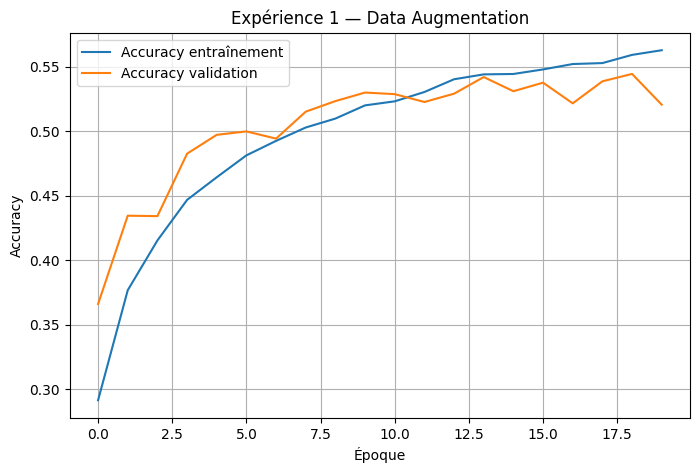

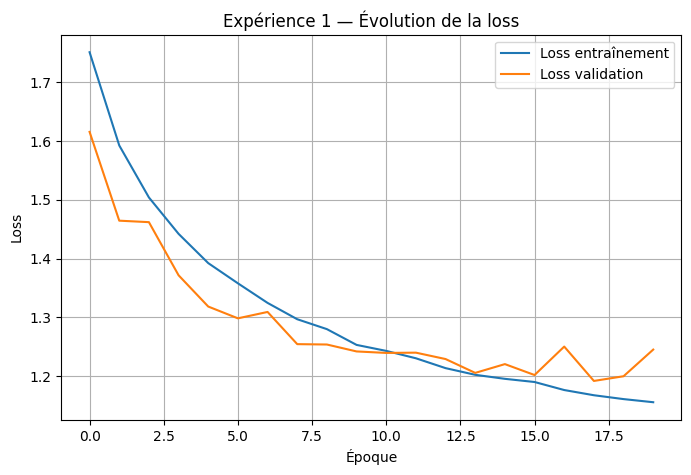

In [ ]:


augmentation_val_accuracy = max(
    history_augmentation.history["val_accuracy"]
)

augmentation_val_loss = min(
    history_augmentation.history["val_loss"]
)

print(f"Meilleure accuracy validation : {augmentation_val_accuracy:.4f}")
print(f"Meilleure loss validation : {augmentation_val_loss:.4f}")

plt.figure(figsize=(8, 5))

plt.plot(
    history_augmentation.history["accuracy"],
    label="Accuracy entraînement"
)

plt.plot(
    history_augmentation.history["val_accuracy"],
    label="Accuracy validation"
)

plt.title("Expérience 1 — Data Augmentation")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    history_augmentation.history["loss"],
    label="Loss entraînement"
)

plt.plot(
    history_augmentation.history["val_loss"],
    label="Loss validation"
)

plt.title("Expérience 1 — Évolution de la loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()

## Expérience 2 : Dropout

Principe : `Dropout(0.5)` désactive aléatoirement 50 % des neurones de la couche dense à chaque étape d'entraînement. Le réseau ne peut plus compter sur quelques neurones et apprend des représentations plus robustes. On le place sur la couche dense, qui concentre la majorité des paramètres et donc le risque de surapprentissage.

In [ ]:
dropout_model = keras.models.Sequential([
    keras.layers.Input(shape=(48, 48, 1)),

    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(128, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Flatten(),

    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.5),

    keras.layers.Dense(7, activation="softmax")
])

dropout_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

dropout_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,847 (1.36 MB)

 Trainable params: 355,847 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Entraînement du modèle avec dropout (20 époques).

In [ ]:

history_dropout = dropout_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

Epoch 1/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.2843 - loss: 1.7637 - val_accuracy: 0.3825 - val_loss: 1.5885
Epoch 2/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.3976 - loss: 1.5493 - val_accuracy: 0.4558 - val_loss: 1.4364
Epoch 3/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4434 - loss: 1.4334 - val_accuracy: 0.4712 - val_loss: 1.3577
Epoch 4/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4768 - loss: 1.3597 - val_accuracy: 0.4976 - val_loss: 1.3071
Epoch 5/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.5020 - loss: 1.3042 - val_accuracy: 0.5173 - val_loss: 1.2655
Epoch 6/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.5232 - loss: 1.2502 - val_accuracy: 0.5269 - val_loss: 1.2470
Epoch 7/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.5378 - loss: 1.2102 - val_accuracy: 0.5245 - val_loss: 1.2320
Epoch 8/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.5535 - loss: 1.1716 - val_accuracy: 

Courbes et meilleurs scores de validation pour l'expérience dropout.

Meilleure accuracy validation : 0.5415
Meilleure loss validation : 1.2197


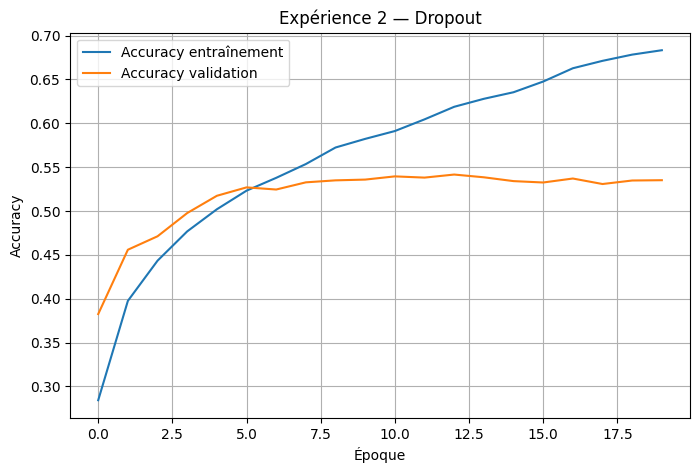

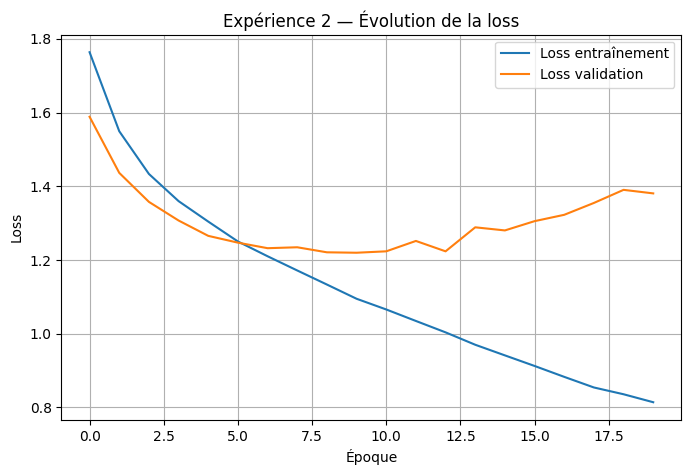

In [ ]:


dropout_val_accuracy = max(history_dropout.history["val_accuracy"])
dropout_val_loss = min(history_dropout.history["val_loss"])

print(f"Meilleure accuracy validation : {dropout_val_accuracy:.4f}")
print(f"Meilleure loss validation : {dropout_val_loss:.4f}")

plt.figure(figsize=(8, 5))

plt.plot(
    history_dropout.history["accuracy"],
    label="Accuracy entraînement"
)

plt.plot(
    history_dropout.history["val_accuracy"],
    label="Accuracy validation"
)

plt.title("Expérience 2 — Dropout")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    history_dropout.history["loss"],
    label="Loss entraînement"
)

plt.plot(
    history_dropout.history["val_loss"],
    label="Loss validation"
)

plt.title("Expérience 2 — Évolution de la loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()

## Expérience 3 : Dropout + data augmentation

Principe : on combine les deux techniques (data augmentation sur les entrées, dropout sur la couche dense) pour voir si leurs effets se cumulent. Les deux régularisent différemment, mais combinées elles peuvent aussi trop contraindre le modèle et ralentir la convergence.

In [ ]:

augmentation_dropout_model = keras.models.Sequential([
    keras.layers.Input(shape=(48, 48, 1)),

    data_augmentation,

    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(128, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Flatten(),

    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.5),

    keras.layers.Dense(7, activation="softmax")
])

augmentation_dropout_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

augmentation_dropout_model.summary()



Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,847 (1.36 MB)

 Trainable params: 355,847 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Entraînement du modèle combiné (20 époques).

In [ ]:


history_augmentation_dropout = augmentation_dropout_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)



Epoch 1/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.2658 - loss: 1.7831 - val_accuracy: 0.3379 - val_loss: 1.6952
Epoch 2/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.3314 - loss: 1.6781 - val_accuracy: 0.4071 - val_loss: 1.5705
Epoch 3/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.3785 - loss: 1.5966 - val_accuracy: 0.4330 - val_loss: 1.4752
Epoch 4/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.4074 - loss: 1.5296 - val_accuracy: 0.4437 - val_loss: 1.4541
Epoch 5/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.4245 - loss: 1.4831 - val_accuracy: 0.4693 - val_loss: 1.3728
Epoch 6/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4409 - loss: 1.4465 - val_accuracy: 0.4956 - val_loss: 1.3201
Epoch 7/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.4540 - loss: 1.4107 - val_accuracy: 0.4978 - val_loss: 1.2963
Epoch 8/20
718/718 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.4677 - loss: 1.3901 - val_ac

Courbes et scores de validation pour la combinaison. On compare ensuite les trois expériences à la baseline CNN pour choisir la meilleure stratégie. *(Attention : les deux lignes `print` de cette cellule affichent les scores de la cellule précédente, `augmentation_val_*`, et non ceux de cette expérience, `augmentation_dropout_val_*`.)*

Meilleure accuracy validation : 0.5443
Meilleure loss validation : 1.1922


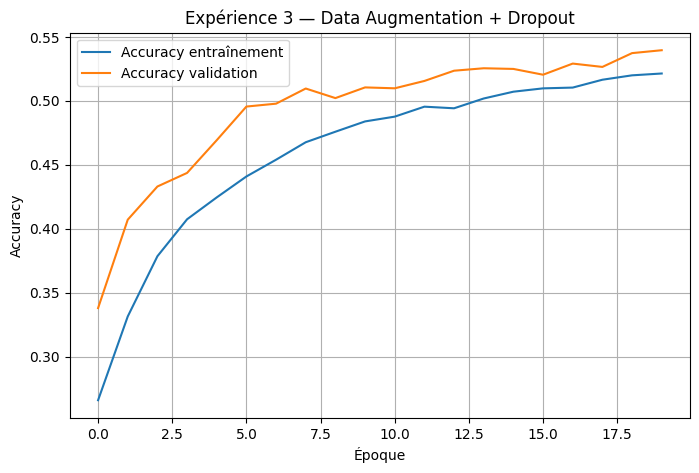

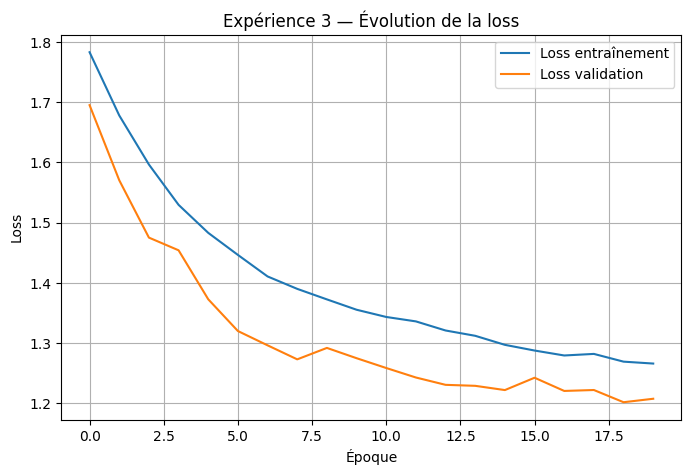

In [ ]:
augmentation_dropout_val_accuracy = max(
    history_augmentation_dropout.history["val_accuracy"]
)

augmentation_dropout_val_loss = min(
    history_augmentation_dropout.history["val_loss"]
)

print(f"Meilleure accuracy validation : {augmentation_val_accuracy:.4f}")
print(f"Meilleure loss validation : {augmentation_val_loss:.4f}")

plt.figure(figsize=(8, 5))

plt.plot(
    history_augmentation_dropout.history["accuracy"],
    label="Accuracy entraînement"
)

plt.plot(
    history_augmentation_dropout.history["val_accuracy"],
    label="Accuracy validation"
)

plt.title("Expérience 3 — Data Augmentation + Dropout")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    history_augmentation_dropout.history["loss"],
    label="Loss entraînement"
)

plt.plot(
    history_augmentation_dropout.history["val_loss"],
    label="Loss validation"
)

plt.title("Expérience 3 — Évolution de la loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()

###Partie 7 : Yolo

In [ ]:
!pip install ultralytics

In [ ]:
from ultralytics import YOLO
import os
import urllib.request

os.makedirs("models", exist_ok=True)

url = "https://github.com/akanametov/yolo-face/releases/download/1.0.0/yolov11n-face.pt"

model_path = "models/yolov11n-face.pt"

if not os.path.exists(model_path):
    urllib.request.urlretrieve(url, model_path)

print("Modèle YOLO chargé :", model_path)

Modèle YOLO chargé : models/yolov11n-face.pt


In [ ]:
face_detector = YOLO(model_path)


image 1/1 /content/04013.png: 448x640 1 face, 13.7ms
Speed: 3.9ms preprocess, 13.7ms inference, 2.0ms postprocess per image at shape (1, 3, 448, 640)


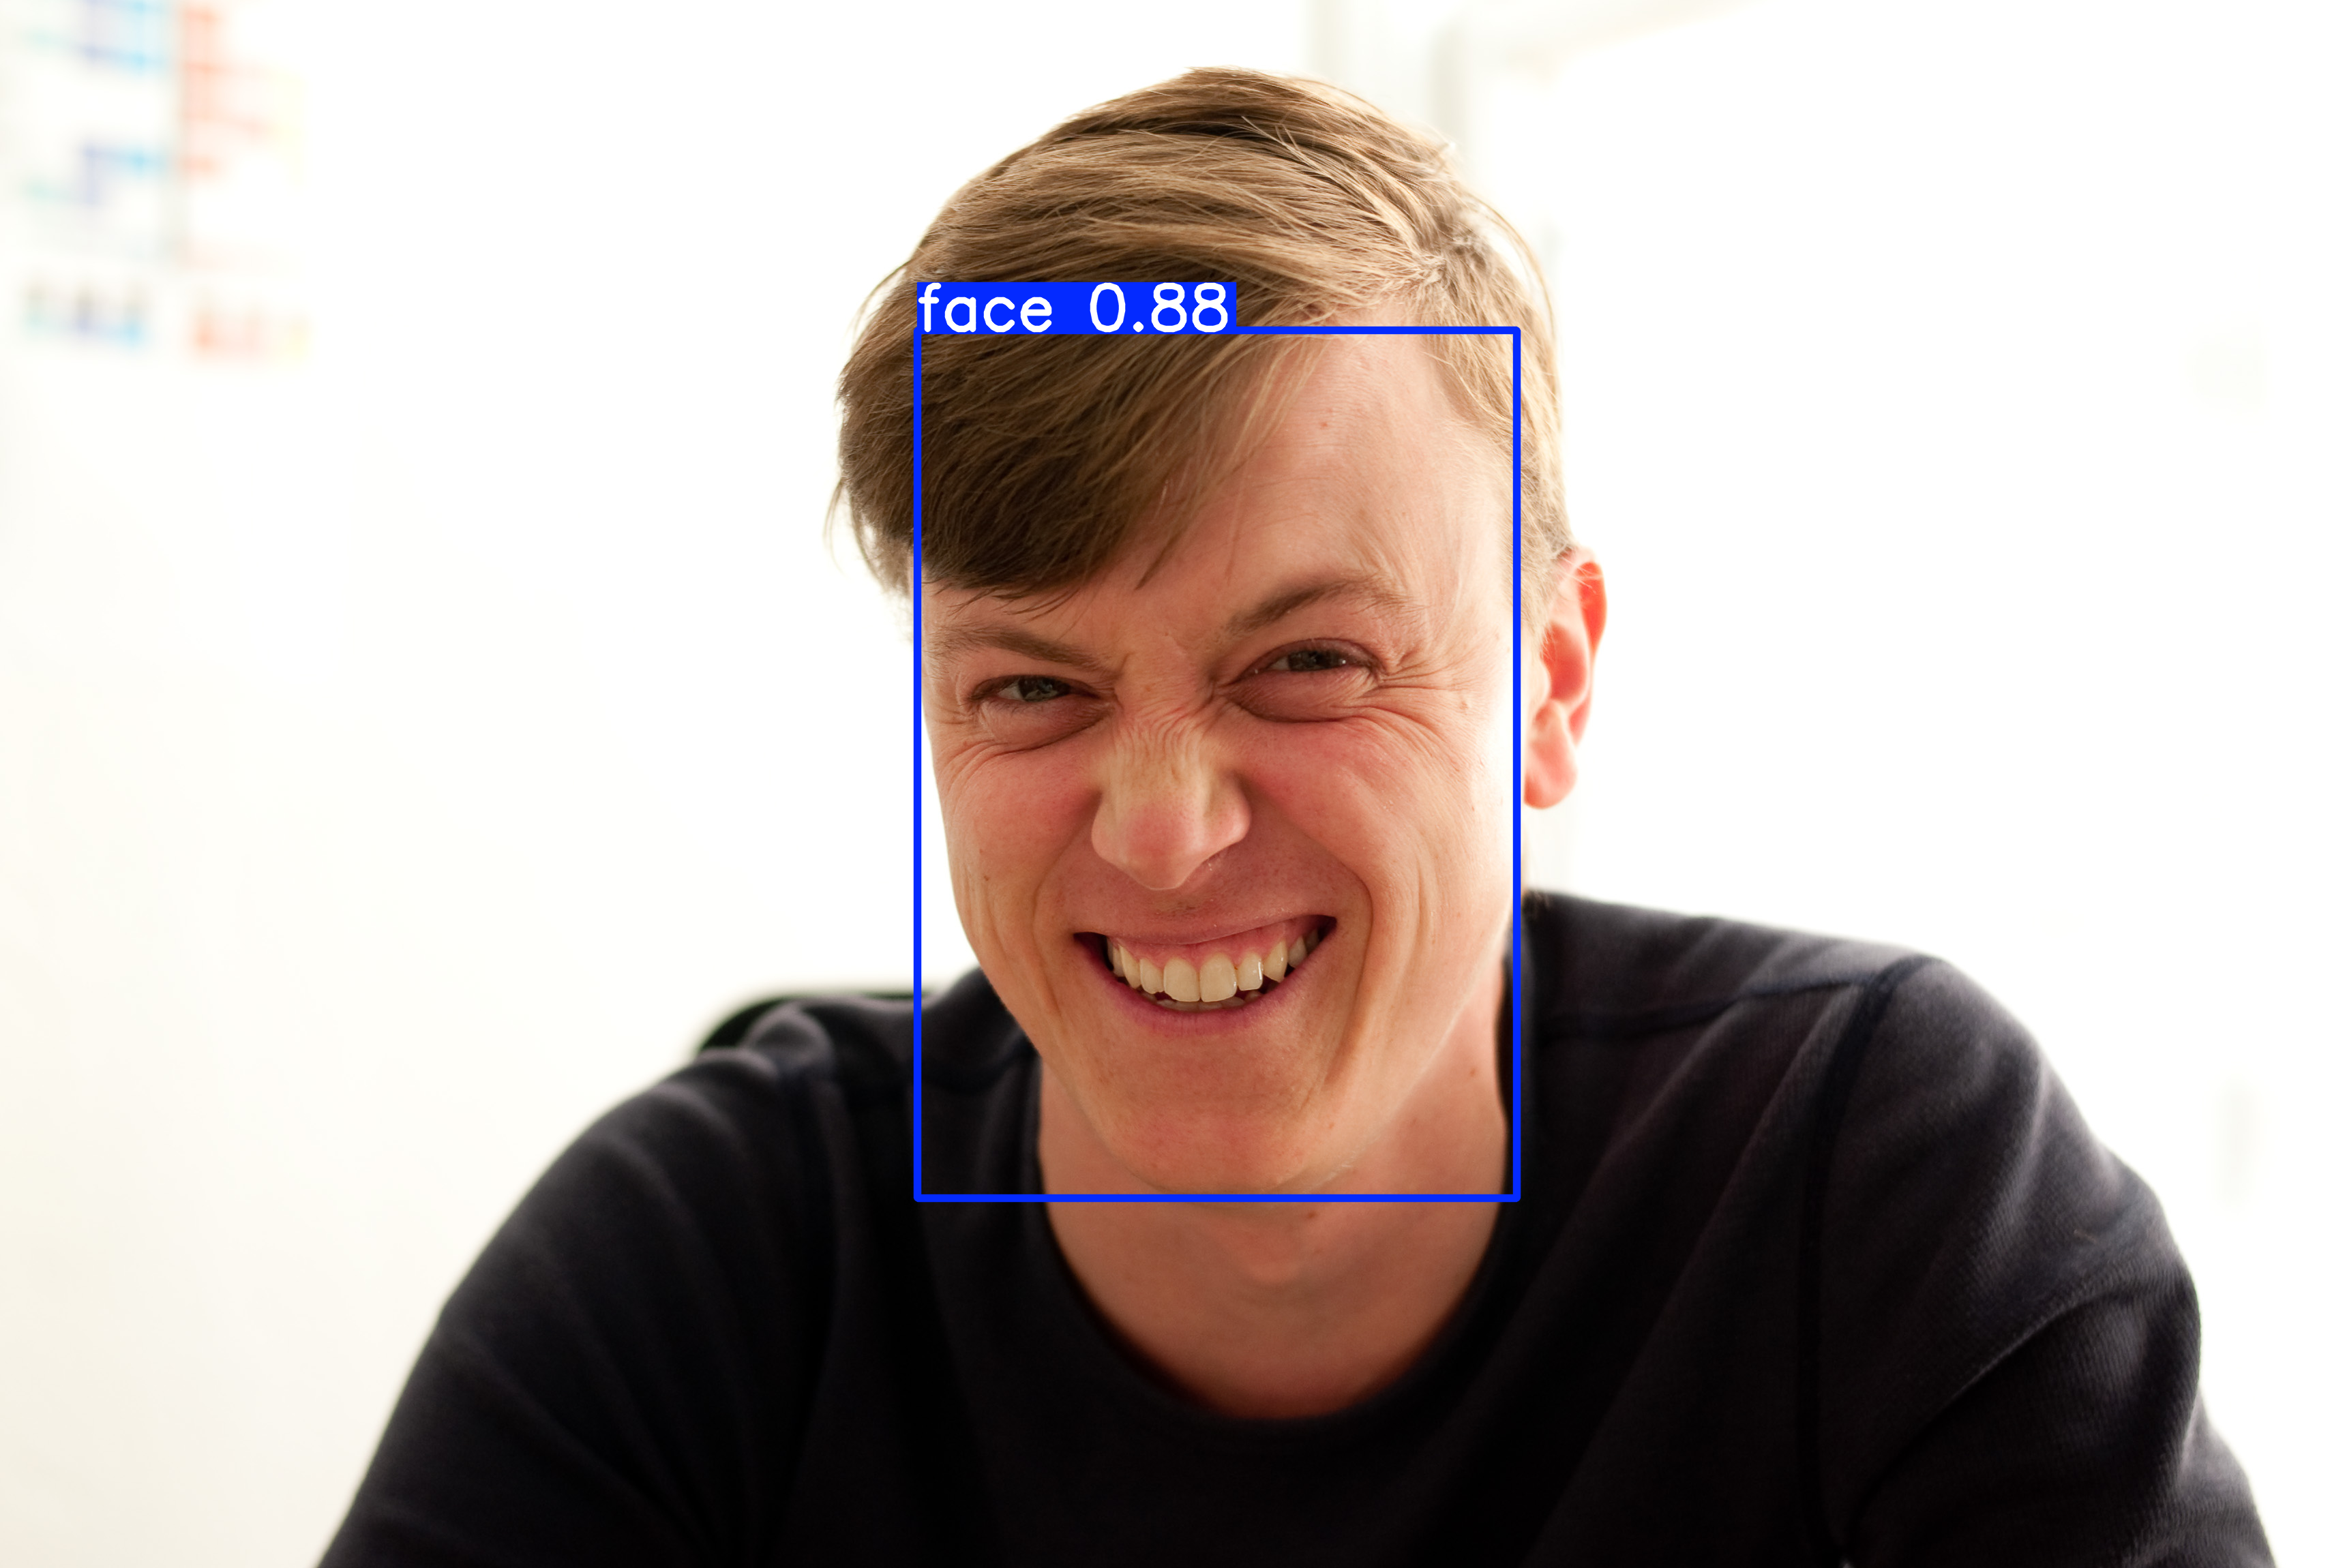

In [ ]:
image_path = "04013.png"
results = face_detector.predict(
    source=image_path,
    conf=0.25
)
results[0].show()

In [ ]:
result = results[0]

boxes = result.boxes.xyxy.cpu().numpy()

print(boxes)

[[     1345.2      484.39      2224.1      1757.5]]


In [ ]:
import cv2

image = cv2.imread(image_path)

print(image.shape)

(2300, 3420, 3)


In [ ]:

x1, y1, x2, y2 = boxes[0].astype(int)

face = image[y1:y2, x1:x2]

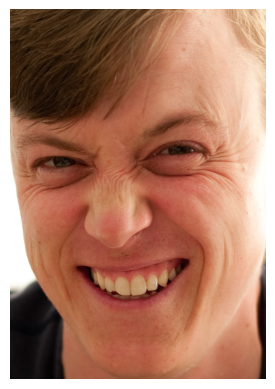

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(cv2.cvtColor(face, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

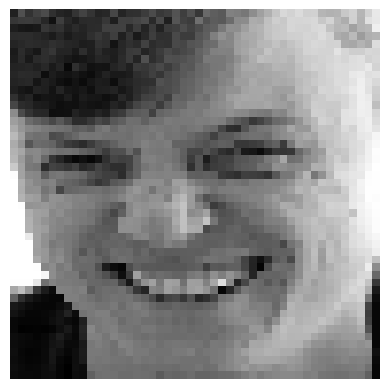

In [ ]:
face_gray = cv2.cvtColor(face, cv2.COLOR_BGR2GRAY)

face_gray = cv2.resize(
    face_gray,
    (48, 48)
)

face_gray = face_gray / 255.0

plt.imshow(face_gray, cmap="gray")
plt.axis("off")
plt.show()

In [ ]:
import numpy as np

face_input = np.expand_dims(face_gray, axis=-1)
face_input = np.expand_dims(face_input, axis=0)

print(face_input.shape)

(1, 48, 48, 1)


In [ ]:
prediction = augmentation_dropout_model.predict(face_input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step


In [ ]:
predicted_class = np.argmax(prediction[0])

print(predicted_class)

3


In [ ]:
# Copie de l'image originale
image_result = image.copy()

# Dimensions de l'image
img_height, img_width = image_result.shape[:2]

emotions = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Neutral",
    "Sad",
    "Surprise"
]

print("Emotion :", emotions[predicted_class])

Emotion : Happy


On peut répéter l'opération complète avec chacune des 6 images pour s'assurer que le modèle fonctionne bien.